# Parte II · Compreender (Checkpoint 2)

**2.1** Sazonalidade diária, semanal e anual em pelo menos quatro figuras de relatório (título que afirma algo, unidades, anotações, uma delas em *small multiples*), e a investigação de **um** padrão intrigante com drill-down e hipóteses ordenadas por plausibilidade.

**2.2** Matriz de perfis diários (um dia por linha, 24 colunas com a média horária), padronização, PCA com scree plot e interpretação dos loadings, projeção por estação e por tipo de dia, e comparação com t-SNE e UMAP (seed fixa).

In [1]:
import warnings
warnings.filterwarnings('ignore', message='IProgress')
warnings.filterwarnings('ignore', message='compatibility_layout')
warnings.filterwarnings('ignore', message='n_jobs value')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.preprocessing import StandardScaler
import umap

from src.dados import carregar_dados, recortar, janela_do_grupo, consumo_diario, SUBMEDICOES
from src.sumario import dados_tratados
from src.perfis import ESTACOES, estacao_do_ano, tipo_de_dia, matriz_perfis

NUMEROS = [53912, 53732]
SEED = sum(NUMEROS)
JANELA = janela_do_grupo(SEED)
inicio, fim = JANELA
DIAS = ['segunda', 'terça', 'quarta', 'quinta', 'sexta', 'sábado', 'domingo']
MESES = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']
COR_DIA = {'dia útil': 'tab:blue', 'fim de semana': 'tab:red'}
COR_ESTACAO = {'inverno': 'tab:blue', 'primavera': 'tab:green', 'verão': 'tab:orange', 'outono': 'tab:brown'}

completo = carregar_dados()
df = recortar(completo, JANELA)
tratado = dados_tratados(df)                      # 1.2 e 1.3: lacunas curtas interpoladas, corrida colada anulada
diario_ok = consumo_diario(tratado, cobertura_min=0.9)
kwh = diario_ok['kWh'].dropna()                   # consumo diário (kWh) dos dias válidos
print(f'Janela: {inicio:%d/%m/%Y} a {fim - pd.Timedelta(minutes=1):%d/%m/%Y} | dias válidos: {len(kwh)} de {len(diario_ok)}')

Janela: 01/02/2008 a 31/07/2009 | dias válidos: 543 de 547


# 2.1 Sazonalidade e um padrão intrigante

Perfis diários: uma linha por dia, 24 colunas. Cada valor é a potência média nessa hora, que em kW é também a energia (kWh) consumida na hora. Descartamos os dias com alguma hora sem leitura (4 dias, ver 1.2). Para as figuras 1 e 4 usamos só os dias "normais" (pelo menos 10 kWh), porque os dias de ausência (1.3) distorceriam o perfil típico; na PCA ficam todos, para ver onde caem.

In [2]:
perfis = matriz_perfis(tratado['Global_active_power'])
tipo = tipo_de_dia(perfis.index)
est = estacao_do_ano(perfis.index)
normal = kwh.reindex(perfis.index) >= 10          # dias com atividade normal (ver 1.3)
perfis_n, tipo_n, est_n = perfis[normal], tipo[normal], est[normal]
print(f'Matriz de perfis: {perfis.shape[0]} dias × {perfis.shape[1]} horas | dias normais: {len(perfis_n)} | ausências (< 10 kWh): {(~normal).sum()}')

Matriz de perfis: 543 dias × 24 horas | dias normais: 502 | ausências (< 10 kWh): 41


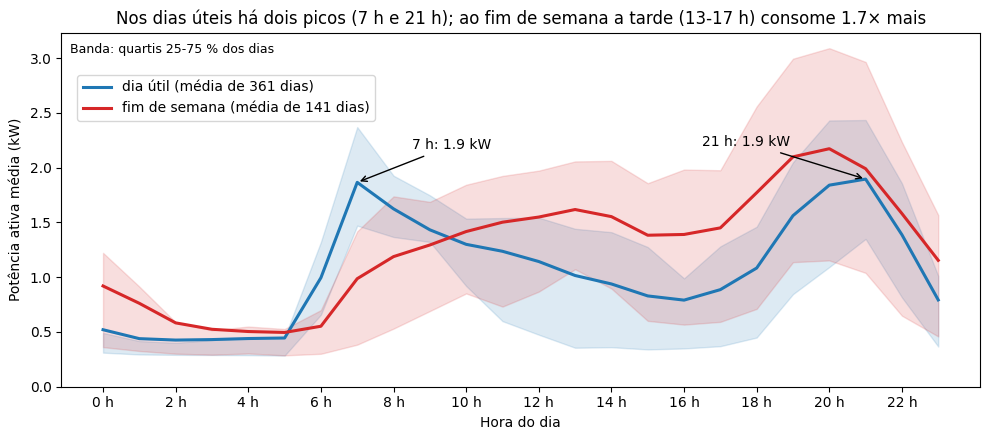

In [3]:
# Figura 1: perfil diário (hora do dia), dias úteis vs fim de semana
fig, ax = plt.subplots(figsize=(10, 4.5))
for t, cor in COR_DIA.items():
    p = perfis_n[tipo_n == t]
    ax.plot(p.columns, p.mean(), color=cor, lw=2.2, label=f'{t} (média de {len(p)} dias)')
    ax.fill_between(p.columns, p.quantile(0.25), p.quantile(0.75), color=cor, alpha=0.15)
du, fs = perfis_n[tipo_n == 'dia útil'].mean(), perfis_n[tipo_n == 'fim de semana'].mean()
h_manha, h_noite = du.loc[5:10].idxmax(), du.loc[17:23].idxmax()
for h, dx in [(h_manha, 1.5), (h_noite, -4.5)]:
    ax.annotate(f'{h} h: {du[h]:.1f} kW', (h, du[h]), xytext=(h + dx, du[h] + 0.3), arrowprops=dict(arrowstyle='->'), fontsize=10)
ax.set_xticks(range(0, 24, 2), [f'{h} h' for h in range(0, 24, 2)])
ax.set_ylim(bottom=0)
ax.set_xlabel('Hora do dia')
ax.set_ylabel('Potência ativa média (kW)')
ax.text(0.01, 0.97, 'Banda: quartis 25-75 % dos dias', transform=ax.transAxes, va='top', fontsize=9)
razao = fs.loc[13:17].mean() / du.loc[13:17].mean()
ax.set_title(f'Nos dias úteis há dois picos ({h_manha} h e {h_noite} h); ao fim de semana a tarde (13-17 h) consome {razao:.1f}× mais')
ax.legend(loc='upper left', bbox_to_anchor=(0.01, 0.9))
plt.tight_layout()
plt.show()

R.: Nos dias úteis o consumo tem dois picos, às 7 h (1,9 kW) e às 21 h (1,9 kW), com um vale a meio da tarde (cerca de 0,8 kW às 16 h) e uma madrugada baixa (0,4 a 0,5 kW). Ao fim de semana o pico da manhã desaparece (às 7 h são 1,0 kW), o consumo sobe devagar até à hora de almoço e mantém-se entre 1,4 e 1,6 kW durante a tarde, 1,7 vezes mais do que nos dias úteis. O pico da noite é também maior (2,2 kW às 20 h) e a madrugada de sábado para domingo é mais alta (0,9 kW às 0 h).

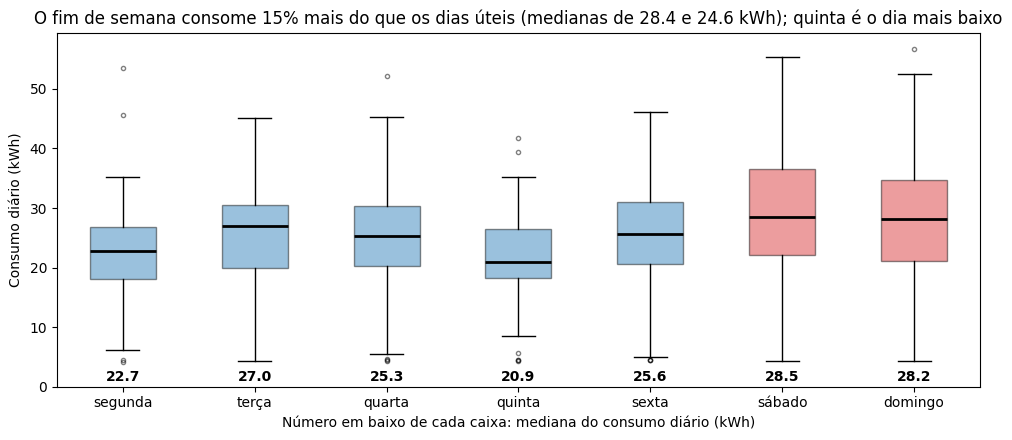

In [4]:
# Figura 2: dia da semana
grupos = [kwh[kwh.index.dayofweek == i] for i in range(7)]
medianas = pd.Series([g.median() for g in grupos], index=DIAS)
fig, ax = plt.subplots(figsize=(10, 4.5))
bp = ax.boxplot(grupos, tick_labels=DIAS, patch_artist=True, medianprops=dict(color='black', lw=2),
                flierprops=dict(markersize=3, alpha=0.5))
for i, caixa in enumerate(bp['boxes']):
    caixa.set_facecolor('tab:red' if i >= 5 else 'tab:blue')
    caixa.set_alpha(0.45)
for i, m in enumerate(medianas, 1):
    ax.text(i, 1, f'{m:.1f}', ha='center', fontsize=10, fontweight='bold')
ax.set_ylim(bottom=0)
ax.set_ylabel('Consumo diário (kWh)')
fs_med, du_med = kwh[kwh.index.dayofweek >= 5].median(), kwh[kwh.index.dayofweek < 5].median()
ax.set_title(f'O fim de semana consome {fs_med / du_med - 1:.0%} mais do que os dias úteis (medianas de {fs_med:.1f} e {du_med:.1f} kWh); {medianas.idxmin()} é o dia mais baixo')
ax.set_xlabel('Número em baixo de cada caixa: mediana do consumo diário (kWh)')
plt.tight_layout()
plt.show()

R.: A mediana do consumo diário é 24,6 kWh nos dias úteis e 28,4 kWh ao fim de semana (+15 %), mas dentro da semana o padrão não é o esperado: a quinta (20,9 kWh) e a segunda (22,7 kWh) são os dias mais baixos, e a terça (27,0 kWh) fica perto do fim de semana (28,5 e 28,2 kWh). As caudas inferiores, até 4 a 6 kWh, são os dias de ausência (1.3). A terça é o padrão que investigamos a seguir.

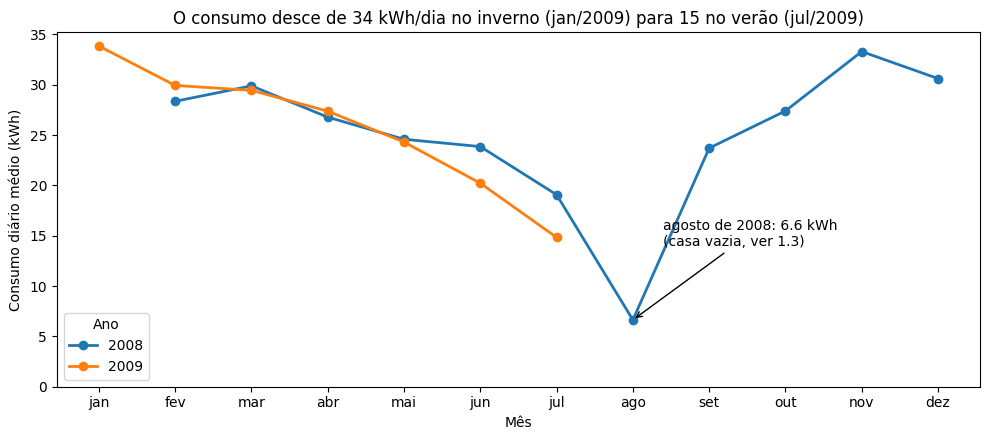

In [5]:
# Figura 3: ciclo anual (consumo diário médio por mês)
mensal = kwh.groupby([kwh.index.year, kwh.index.month]).mean().unstack(0)
serie = mensal.stack()
(m_max, a_max), (m_min, a_min) = serie.idxmax(), serie.drop((8, 2008)).idxmin()   # (mês, ano)
fig, ax = plt.subplots(figsize=(10, 4.5))
for ano, cor in [(2008, 'tab:blue'), (2009, 'tab:orange')]:
    ax.plot(mensal.index, mensal[ano], marker='o', color=cor, lw=2, label=str(ano))
ax.annotate(f'agosto de 2008: {mensal.loc[8, 2008]:.1f} kWh\n(casa vazia, ver 1.3)', (8, mensal.loc[8, 2008]),
            xytext=(8.4, 14), arrowprops=dict(arrowstyle='->'), fontsize=10)
ax.set_xticks(range(1, 13), MESES)
ax.set_ylim(bottom=0)
ax.set_xlabel('Mês')
ax.set_ylabel('Consumo diário médio (kWh)')
ax.set_title(f'O consumo desce de {mensal.max().max():.0f} kWh/dia no inverno ({MESES[m_max - 1]}/{a_max}) para {serie.drop((8, 2008)).min():.0f} no verão ({MESES[m_min - 1]}/{a_min})')
ax.legend(title='Ano')
plt.tight_layout()
plt.show()

R.: O consumo diário médio é máximo no outono-inverno (34 kWh em janeiro de 2009 e 33 kWh em novembro de 2008) e mínimo no verão (15 kWh em julho de 2009). Nos meses que a janela cobre duas vezes (fevereiro a julho) as curvas de 2008 e 2009 quase coincidem até maio, e em junho e julho de 2009 o consumo fica cerca de 4 kWh abaixo do de 2008 (20,2 contra 23,9 e 14,8 contra 19,1). Agosto de 2008 (6,6 kWh) é o ponto fora da curva, pela ausência. Com um ciclo anual incompleto não separamos o efeito das estações de uma eventual tendência de descida ou de mudanças na casa: só podemos dizer que o início do verão de 2009 é mais baixo do que o de 2008.

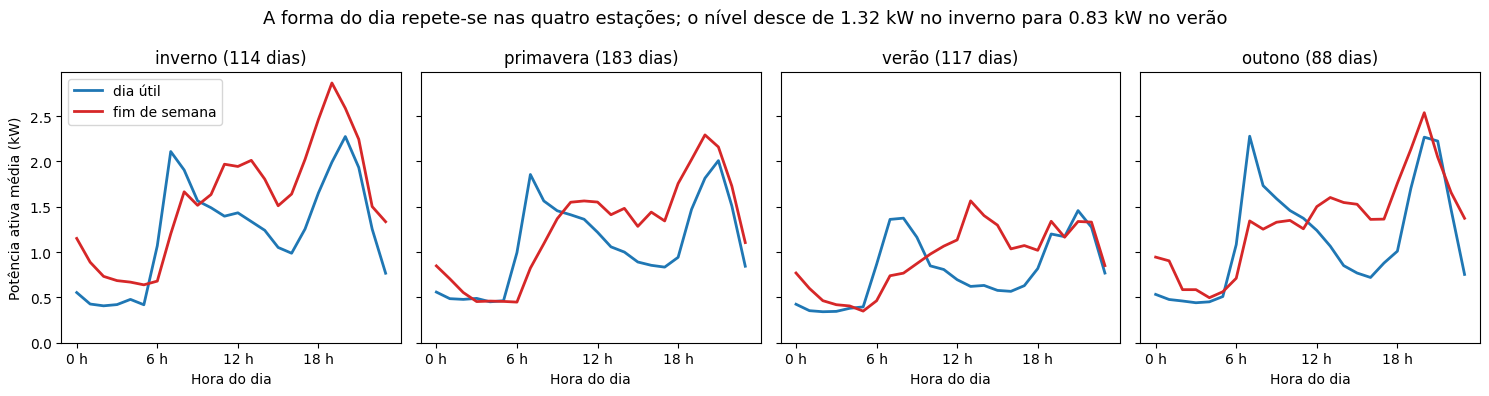

In [6]:
# Figura 4 (small multiples): o perfil diário em cada estação
fig, eixos = plt.subplots(1, 4, figsize=(15, 4), sharey=True)
for ax, e in zip(eixos, ESTACOES):
    for t, cor in COR_DIA.items():
        p = perfis_n[(est_n == e) & (tipo_n == t)]
        ax.plot(p.columns, p.mean(), color=cor, lw=2, label=t)
    ax.set_title(f'{e} ({(est_n == e).sum()} dias)')
    ax.set_xticks(range(0, 24, 6), [f'{h} h' for h in range(0, 24, 6)])
    ax.set_xlabel('Hora do dia')
    ax.set_ylim(bottom=0)
eixos[0].set_ylabel('Potência ativa média (kW)')
eixos[0].legend(loc='upper left')
nivel = {e: perfis_n[est_n == e].mean().mean() for e in ESTACOES}
fig.suptitle(f'A forma do dia repete-se nas quatro estações; o nível desce de {nivel["inverno"]:.2f} kW no inverno para {nivel["verão"]:.2f} kW no verão', fontsize=13)
plt.tight_layout()
plt.show()

R.: A forma do dia é parecida em todas as estações: nos dias úteis, um pico de manhã e outro ao fim do dia; ao fim de semana, um planalto a meio do dia e um pico ao fim da tarde. O que muda é o nível e a altura dos picos. A média do perfil desce de 1,32 kW no inverno para 0,83 kW no verão; no verão o pico da manhã dos dias úteis é bastante mais baixo (1,4 kW, contra 2,1 a 2,3 kW no inverno e no outono) e o da noite é o mais baixo do ano. O pico do fim da tarde ao fim de semana é máximo no inverno (2,9 kW).

## Padrão intrigante: a terça-feira consome muito mais do que a quinta

Na figura 2 as medianas dos dias úteis não são iguais: a terça fica bem acima da segunda e da quinta. Em 1.3 já tínhamos visto que 27 dos 133 picos extremos aconteciam à terça (contra 7 à segunda e 9 à quinta). Um dia útil pode comportar-se como fim de semana? Fazemos o drill-down em quatro passos: confirmar o efeito, ver a que horas acontece, ver que circuito o explica e ordenar as hipóteses.

**Passo 1: o efeito é real e estável?** Comparamos terça e quinta nos dias normais (≥ 10 kWh), com um teste de Mann-Whitney (não assume normalidade) e por trimestre, para ver se não é um período isolado.

In [7]:
normais = kwh[kwh >= 10]
terca = normais[normais.index.dayofweek == 1]
quinta = normais[normais.index.dayofweek == 3]
u = stats.mannwhitneyu(terca, quinta)
print(f'Terça: mediana {terca.median():.1f} kWh (n = {len(terca)}) | Quinta: mediana {quinta.median():.1f} kWh (n = {len(quinta)}) | Mann-Whitney p = {u.pvalue:.4f}')

trimestre = normais.groupby([normais.index.to_period('Q'), normais.index.dayofweek]).mean().unstack()[[1, 3]]
trimestre.columns = ['terça', 'quinta']
trimestre['terça/quinta'] = trimestre['terça'] / trimestre['quinta']
print(f"Trimestres com terça acima da quinta: {(trimestre['terça/quinta'] > 1).sum()} de {len(trimestre)}")
trimestre.round(2)

Terça: mediana 27.4 kWh (n = 74) | Quinta: mediana 22.4 kWh (n = 71) | Mann-Whitney p = 0.0015
Trimestres com terça acima da quinta: 5 de 7


,terça,quinta,terça/quinta
instante,,,
2008Q1,34.26,27.52,1.24
2008Q2,28.43,21.47,1.32
2008Q3,19.10,20.45,0.93
2008Q4,30.49,26.53,1.15
2009Q1,28.88,23.92,1.21
2009Q2,24.39,22.72,1.07
2009Q3,15.58,16.30,0.96


**Passo 2: a que horas?** Perfil horário médio de terça e de quinta (dias normais) e a diferença entre os dois.

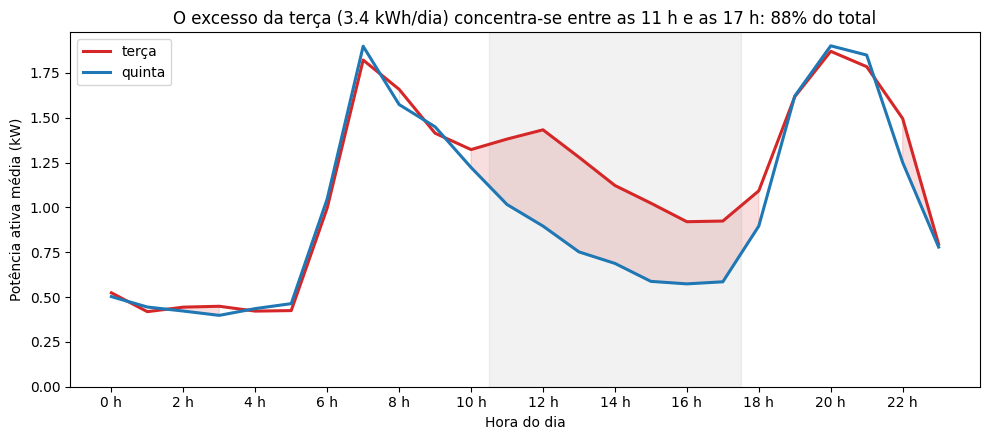

In [8]:
pt = perfis_n[perfis_n.index.dayofweek == 1].mean()
pq = perfis_n[perfis_n.index.dayofweek == 3].mean()
dif = pt - pq
h0, h1 = 11, 17
fracao = dif.loc[h0:h1].sum() / dif.sum()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(pt.index, pt, color='tab:red', lw=2.2, label='terça')
ax.plot(pq.index, pq, color='tab:blue', lw=2.2, label='quinta')
ax.fill_between(pt.index, pq, pt, where=pt > pq, color='tab:red', alpha=0.15)
ax.axvspan(h0 - 0.5, h1 + 0.5, color='grey', alpha=0.1)
ax.set_xticks(range(0, 24, 2), [f'{h} h' for h in range(0, 24, 2)])
ax.set_ylim(bottom=0)
ax.set_xlabel('Hora do dia')
ax.set_ylabel('Potência ativa média (kW)')
ax.set_title(f'O excesso da terça ({dif.sum():.1f} kWh/dia) concentra-se entre as {h0} h e as {h1} h: {fracao:.0%} do total')
ax.legend()
plt.tight_layout()
plt.show()

**Passo 3: que circuito?** Decompomos o consumo diário pelas três submedições e pela energia não medida (o que sobra do total, `Global_active_power × 1000 / 60 − Σ submedições`, em Wh por minuto).

,cozinha,lavandaria,termoacumulador e ar cond.,não medida
segunda,1.01,1.04,8.85,12.96
terça,1.21,2.03,10.15,13.23
quarta,1.75,2.50,9.03,13.02
quinta,1.08,0.73,8.66,12.78
sexta,1.47,1.38,10.37,13.11
sábado,2.54,2.29,11.09,15.19
domingo,2.89,2.91,8.45,15.49


Dias com a máquina da lavandaria a trabalhar: {'segunda': 23, 'terça': 51, 'quarta': 59, 'quinta': 15, 'sexta': 38, 'sábado': 68, 'domingo': 73}


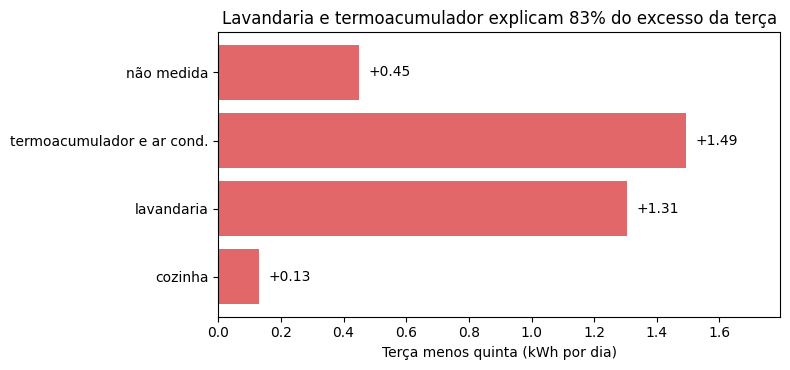

In [9]:
t = tratado.copy()
t['nao_medida'] = t['Global_active_power'] * 1000 / 60 - t[SUBMEDICOES].sum(axis=1)
circ = (t[SUBMEDICOES + ['nao_medida']].resample('D').mean() * 1440 / 1000).loc[normais.index]    # kWh por dia
circ.columns = ['cozinha', 'lavandaria', 'termoacumulador e ar cond.', 'não medida']
por_dia = circ.groupby(circ.index.dayofweek).mean()
por_dia.index = DIAS
excesso = por_dia.loc['terça'] - por_dia.loc['quinta']
display(por_dia.round(2))

lavagem = (t['Sub_metering_2'] > 30).resample('D').max().astype(bool).loc[normais.index]    # dia com pelo menos 1 minuto > 30 Wh (máquina ligada)
frac_lav = lavagem.groupby(lavagem.index.dayofweek).mean()
frac_lav.index = DIAS
print('Dias com a máquina da lavandaria a trabalhar:', (100 * frac_lav).round(0).astype(int).to_dict())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(excesso.index, excesso.values, color='tab:red', alpha=0.7)
for i, v in enumerate(excesso.values):
    ax.text(v + 0.03, i, f'{v:+.2f}', va='center')
ax.set_xlim(0, excesso.max() * 1.2)
ax.set_xlabel('Terça menos quinta (kWh por dia)')
top2 = (excesso['lavandaria'] + excesso['termoacumulador e ar cond.']) / excesso.sum()
ax.set_title(f'Lavandaria e termoacumulador explicam {top2:.0%} do excesso da terça')
plt.tight_layout()
plt.show()

R.: **O efeito é real e estável.** A mediana da terça (27,4 kWh) está 5 kWh acima da da quinta (22,4 kWh) (Mann-Whitney, p = 0,0015, 74 terças contra 71 quintas), e a terça fica acima da quinta em 5 dos 7 trimestres. As duas exceções são os trimestres de verão (julho a setembro de 2008 e de 2009), em que o consumo é baixo todos os dias e a razão é 0,93 e 0,96. Ressalva: escolhemos comparar a terça com a quinta depois de ver que eram o dia útil mais alto e o mais baixo, por isso o p não é o de um teste planeado. Corrigindo para as 10 comparações possíveis entre dias úteis (Bonferroni), fica p = 0,015, ainda abaixo de 0,05.

**Acontece a meio do dia.** Os dois perfis coincidem de madrugada, de manhã e ao fim do dia; o excesso da terça (3,4 kWh por dia) concentra-se entre as 11 h e as 17 h (88 %).

**Vem do termoacumulador e da lavandaria.** Dos 3,4 kWh de diferença, 1,5 vêm do termoacumulador e do ar condicionado, 1,3 da lavandaria, 0,5 da energia não medida e 0,1 da cozinha. A máquina da lavandaria (minutos acima de 30 Wh) trabalha em 51 % das terças, contra 15 % das quintas; à quarta (59 %), ao sábado (68 %) e ao domingo (73 %) acontece ainda mais.

**Hipóteses, da mais para a menos plausível:**

1. *Há alguém em casa à terça (e à quarta) durante o dia*, por exemplo por ser um dia de folga ou de trabalho em casa. Explica o excesso ao meio-dia e à tarde em dois circuitos ao mesmo tempo (lavandaria e água quente), e a terça já aparecia com mais picos extremos em 1.3 (27, contra 7 à segunda e 9 à quinta). É coerente com os dados, mas não distingue "alguém em casa" de "alguém que lava roupa à terça".
2. *Lavagem de roupa concentrada em certos dias por rotina* (terça, quarta, fim de semana). Explica a lavandaria (1,3 kWh), mas não explica sozinha o termoacumulador (1,5 kWh): teria de haver água quente associada à lavagem.
3. *Feriados e pontes à segunda ou à terça.* Não a conseguimos excluir porque não temos o calendário de feriados. Com 74 terças e testes com a mediana, que é pouco sensível a um ou outro dia, poucos feriados não explicam uma diferença de 5 kWh.
4. *Artefacto da amostra* (mais terças em meses frios). Pouco plausível: há 74 terças e 71 quintas repartidas pelos trimestres e o efeito aparece em 5 dos 7.

**O que falta para decidir:** o calendário de feriados (hipótese 3), as temperaturas (a água quente e o ar condicionado dependem delas) e um dado sobre presença, que não temos. A hipótese 1 liga-se à pergunta livre: se a ocupação deixa marca no consumo, deve ser possível detetá-la.

# 2.2 Perfis diários, PCA, t-SNE e UMAP

Cada dia é um ponto num espaço de 24 dimensões (uma por hora). A PCA, o t-SNE e o UMAP procuram um mapa de 2 dimensões onde dias parecidos fiquem perto. Usamos todos os dias completos, incluindo as ausências, para ver onde caem.

**Padronização.** Aplicamos `StandardScaler` (média 0, desvio-padrão 1 em cada hora). Sem isto, as horas de maior variância (o fim da tarde) dominariam a PCA; com isto, cada hora pesa o mesmo, incluindo as da madrugada, onde a variância é pequena e há mais ruído relativo. Testamos a sensibilidade a esta escolha.

Variância explicada: PC1 27.9%, PC2 13.8%, PC3 11.5% | acumulada PC1-3: 53.2%
Componentes para 80 %: 9 | para 90 %: 14
PC1: variância explicada 27.9% (padronizada) vs 36.6% (só centrada) | |cos| entre loadings = 0.94
PC2: variância explicada 13.8% (padronizada) vs 12.6% (só centrada) | |cos| entre loadings = 0.26
PC3: variância explicada 11.5% (padronizada) vs 10.3% (só centrada) | |cos| entre loadings = 0.41


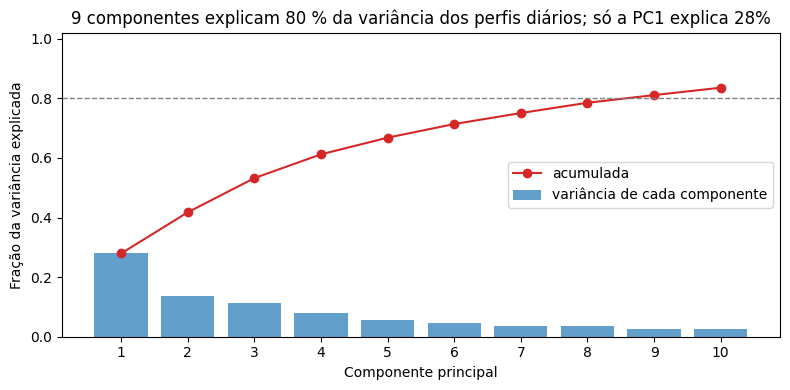

In [10]:
X = perfis.to_numpy()
Z = StandardScaler().fit_transform(X)
pca = PCA(random_state=SEED).fit(Z)
pcs = pca.transform(Z)
var = pca.explained_variance_ratio_
acum = var.cumsum()
n80, n90 = int(np.argmax(acum >= 0.8)) + 1, int(np.argmax(acum >= 0.9)) + 1
print(f'Variância explicada: PC1 {var[0]:.1%}, PC2 {var[1]:.1%}, PC3 {var[2]:.1%} | acumulada PC1-3: {acum[2]:.1%}')
print(f'Componentes para 80 %: {n80} | para 90 %: {n90}')

# sensibilidade à padronização: PCA só centrada (sem dividir pelo desvio-padrão)
pca_c = PCA(random_state=SEED).fit(X)
for k in range(3):
    cos = abs(np.dot(pca.components_[k], pca_c.components_[k]))
    print(f'PC{k + 1}: variância explicada {var[k]:.1%} (padronizada) vs {pca_c.explained_variance_ratio_[k]:.1%} (só centrada) | |cos| entre loadings = {cos:.2f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, 11), var[:10], color='tab:blue', alpha=0.7, label='variância de cada componente')
ax.plot(range(1, 11), acum[:10], 'o-', color='tab:red', label='acumulada')
ax.axhline(0.8, color='grey', ls='--', lw=1)
ax.set_xticks(range(1, 11))
ax.set_xlabel('Componente principal')
ax.set_ylabel('Fração da variância explicada')
ax.set_ylim(0, 1.02)
ax.set_title(f'{n80} componentes explicam 80 % da variância dos perfis diários; só a PC1 explica {var[0]:.0%}')
ax.legend(loc='center right')
plt.tight_layout()
plt.show()

R.: A variância dos perfis diários está espalhada: a PC1 explica 27,9 %, a PC2 13,8 % e a PC3 11,5 % (53,2 % no total), e são precisas 9 componentes para chegar a 80 % e 14 para 90 %. Um mapa de duas dimensões guarda assim menos de metade da informação (41,7 %), e os gráficos que se seguem têm de ser lidos com essa reserva.

A padronização importa. Sem dividir pelo desvio-padrão, a PC1 sobe para 36,6 % (as horas de pico dominam) e o seu loading quase não muda (|cos| = 0,94), mas a PC2 e a PC3 mudam muito (|cos| = 0,26 e 0,41). Só a interpretação da PC1 é robusta a esta escolha; a da PC2 e da PC3 vale para a versão padronizada.

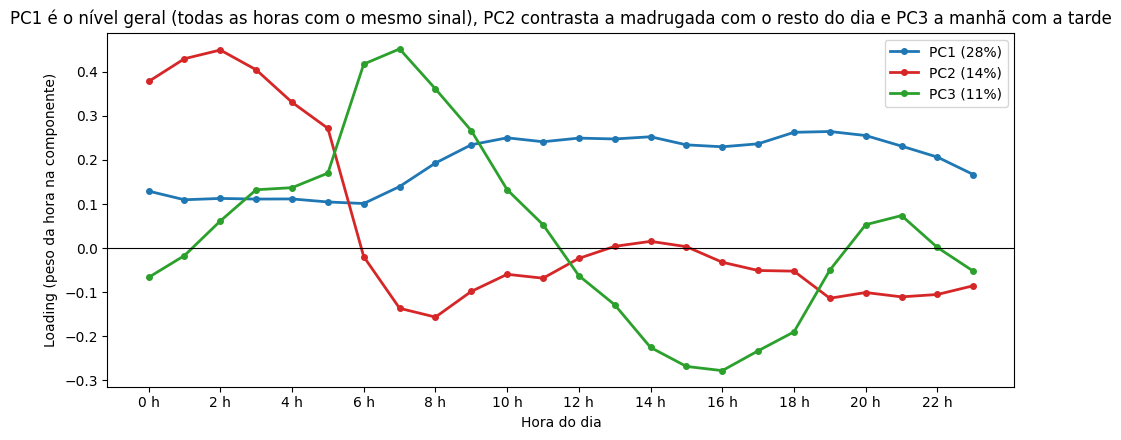

Horas com maior |loading|:
PC1 [19, 18, 20, 14] | sinal das 4 maiores: [1, 1, 1, 1]
PC2 [2, 1, 3, 0] | sinal das 4 maiores: [1, 1, 1, 1]
PC3 [7, 6, 8, 16] | sinal das 4 maiores: [1, 1, 1, -1]


In [11]:
# Loadings das três primeiras componentes por hora do dia
fig, ax = plt.subplots(figsize=(10, 4.5))
for k, cor in enumerate(['tab:blue', 'tab:red', 'tab:green']):
    ax.plot(range(24), pca.components_[k], marker='o', ms=4, color=cor, lw=2, label=f'PC{k + 1} ({var[k]:.0%})')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(range(0, 24, 2), [f'{h} h' for h in range(0, 24, 2)])
ax.set_xlabel('Hora do dia')
ax.set_ylabel('Loading (peso da hora na componente)')
ax.set_title('PC1 é o nível geral (todas as horas com o mesmo sinal), PC2 contrasta a madrugada com o resto do dia e PC3 a manhã com a tarde')
ax.legend()
plt.tight_layout()
plt.show()

load = pd.DataFrame(pca.components_[:3].T, columns=['PC1', 'PC2', 'PC3'], index=range(24))
print('Horas com maior |loading|:')
for c_ in load:
    print(c_, load[c_].abs().nlargest(4).index.tolist(), '| sinal das 4 maiores:', np.sign(load[c_][load[c_].abs().nlargest(4).index]).astype(int).tolist())

R.: **PC1 (28 %) é o nível geral de consumo.** Todos os loadings são positivos, de 0,10 de madrugada a 0,26 ao fim da tarde: um dia com PC1 alta consome mais em todas as horas, sobretudo das 10 h às 22 h.

**PC2 (14 %) contrasta a madrugada com o resto do dia.** Os loadings são de +0,3 a +0,45 entre as 0 h e as 5 h e ligeiramente negativos depois das 6 h. Uma PC2 alta é um dia com a madrugada ativa e o resto normal.

**PC3 (12 %) contrasta a manhã com a tarde.** O loading é +0,45 às 7 h e −0,28 às 16 h. Uma PC3 alta é um dia com o consumo concentrado de manhã e pouco à tarde. Os dias confirmam a leitura: a mediana da PC3 é +0,66 nos dias úteis e −1,44 ao fim de semana, quando o consumo passa da manhã para a tarde.

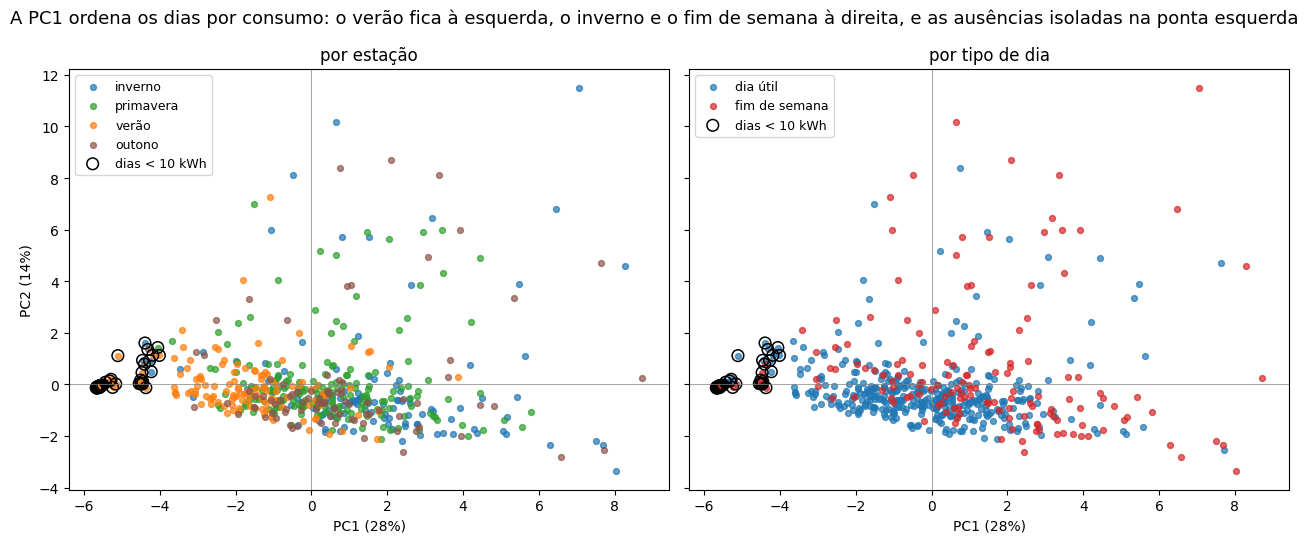

,PC1,PC2,PC3
estação,,,
inverno,1.30,-0.65,0.13
outono,0.45,-0.69,0.88
primavera,0.42,-0.38,0.38
verão,-2.03,-0.12,-0.45


,PC1,PC2,PC3
tipo,,,
dia útil,-0.28,-0.49,0.66
fim de semana,0.94,-0.09,-1.44


Ausências: PC1 mediana -5.32 | restantes: 0.28


In [12]:
# Projeção PC1 × PC2 por estação e por tipo de dia
aus = (kwh.reindex(perfis.index) < 10).to_numpy()
est_all, tipo_all = estacao_do_ano(perfis.index).to_numpy(), tipo_de_dia(perfis.index).to_numpy()

fig, eixos = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for e, cor in COR_ESTACAO.items():
    m = est_all == e
    eixos[0].scatter(pcs[m, 0], pcs[m, 1], s=18, color=cor, alpha=0.7, label=e)
for t_, cor in COR_DIA.items():
    m = tipo_all == t_
    eixos[1].scatter(pcs[m, 0], pcs[m, 1], s=18, color=cor, alpha=0.7, label=t_)
for ax in eixos:
    ax.scatter(pcs[aus, 0], pcs[aus, 1], s=70, facecolors='none', edgecolors='black', lw=1.1, label='dias < 10 kWh')
    ax.set_xlabel(f'PC1 ({var[0]:.0%})')
    ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    ax.legend(fontsize=9)
eixos[0].set_ylabel(f'PC2 ({var[1]:.0%})')
eixos[0].set_title('por estação'); eixos[1].set_title('por tipo de dia')
fig.suptitle('A PC1 ordena os dias por consumo: o verão fica à esquerda, o inverno e o fim de semana à direita, e as ausências isoladas na ponta esquerda', fontsize=13)
plt.tight_layout()
plt.show()

# separação por grupo na PC1 e na PC2 (mediana de cada grupo)
res = pd.DataFrame({'PC1': pcs[:, 0], 'PC2': pcs[:, 1], 'PC3': pcs[:, 2], 'estação': est_all, 'tipo': tipo_all, 'ausência': aus})
display(res.groupby('estação')[['PC1', 'PC2', 'PC3']].median().round(2))
display(res.groupby('tipo')[['PC1', 'PC2', 'PC3']].median().round(2))
print('Ausências: PC1 mediana', res.loc[res['ausência'], 'PC1'].median().round(2), '| restantes:', res.loc[~res['ausência'], 'PC1'].median().round(2))

R.: A PC1 funciona como eixo de intensidade: a mediana da PC1 é −2,0 no verão, +0,4 na primavera e no outono e +1,3 no inverno, e −0,3 nos dias úteis contra +0,9 ao fim de semana. Os 41 dias de ausência (círculos) são o único grupo claramente separado, na ponta esquerda (PC1 mediana de −5,3, contra +0,3 nos restantes). De resto os dias formam uma nuvem contínua em que as estações e os tipos de dia se sobrepõem muito: a PCA não separa classes, só gradua o consumo. A PC2 tem uma cauda de dias com valores altos (até 11, madrugada muito ativa) que não corresponde a nenhuma estação em particular.

## Comparação com t-SNE e UMAP

Os dois são métodos não lineares que preservam a vizinhança (dias parecidos ficam juntos) à custa das distâncias globais. Duas métricas, calculadas no espaço padronizado de 24 dimensões:

- **trustworthiness** (k = 10): fração dos vizinhos próximos no mapa que também o são no espaço original (1 = perfeito; mede a preservação **local**).
- **correlação de Spearman entre distâncias**: entre todos os pares de dias, as distâncias no mapa acompanham as originais? (mede a preservação **global**).

Seed fixa (`random_state = SEED`) em ambos.

,trustworthiness,Spearman das distâncias
PCA,0.785,0.771
t-SNE (perplexidade 30),0.916,0.605
UMAP (15 vizinhos),0.893,0.538


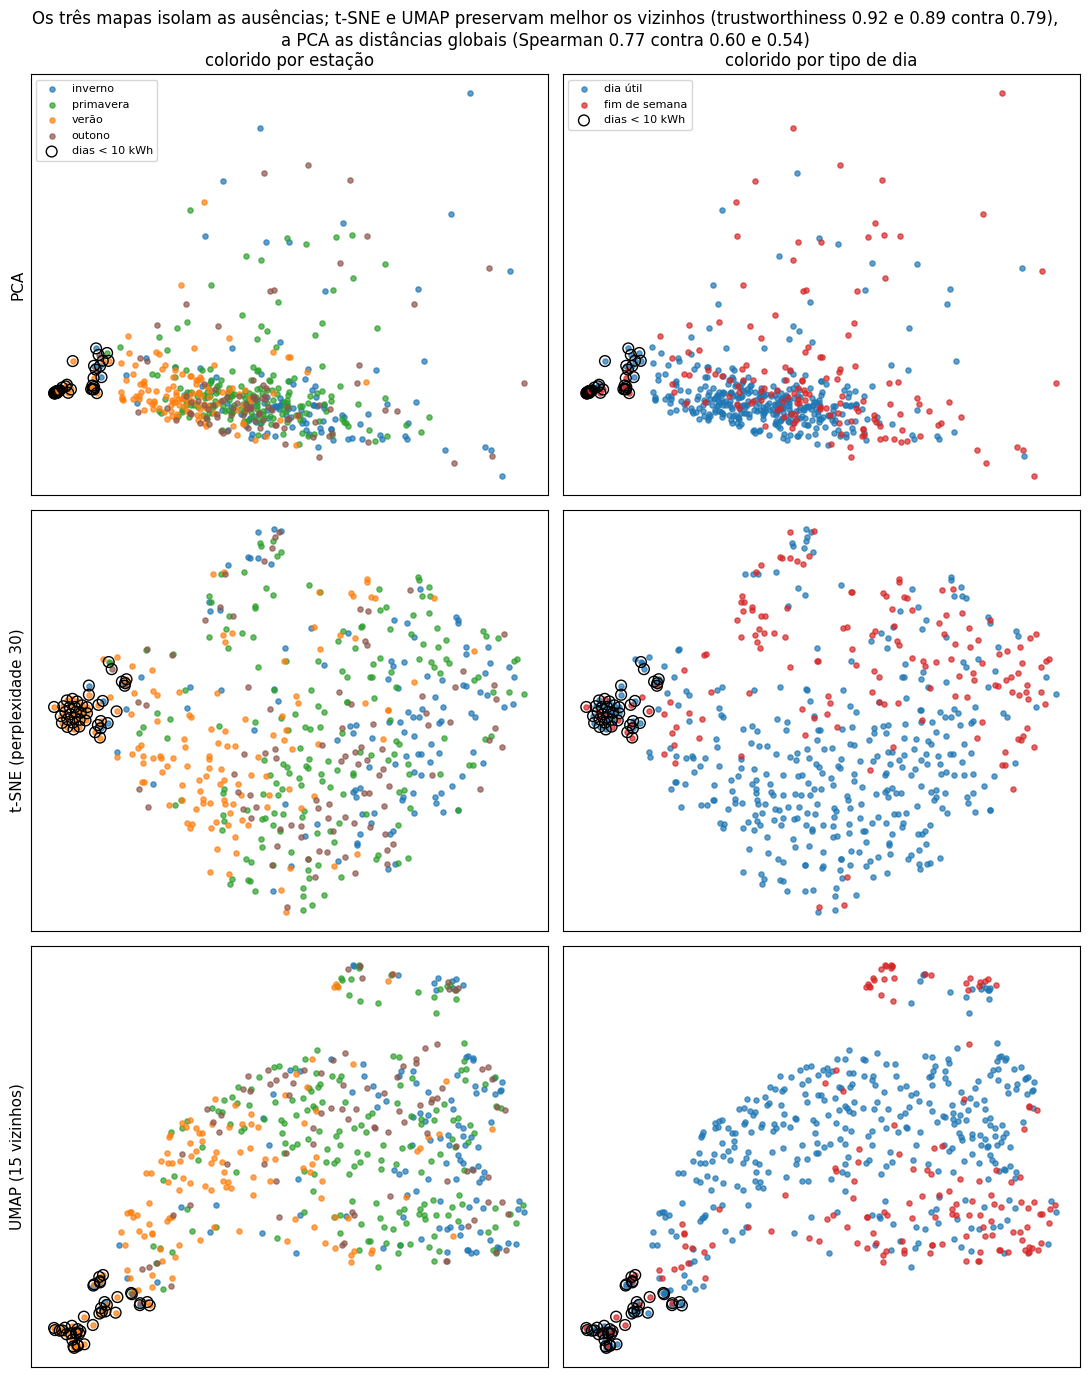

In [13]:
def avaliar(Y, k=10):
    return {'trustworthiness': trustworthiness(Z, Y, n_neighbors=k),
            'Spearman das distâncias': stats.spearmanr(pdist(Z), pdist(Y)).statistic}

tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED).fit_transform(Z)
emb_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(Z)
mapas = {'PCA': pcs[:, :2], 't-SNE (perplexidade 30)': tsne, 'UMAP (15 vizinhos)': emb_umap}

metricas = pd.DataFrame({nome: avaliar(Y) for nome, Y in mapas.items()}).T
display(metricas.round(3))

fig, eixos = plt.subplots(3, 2, figsize=(11, 14))
for linha, (nome, Y) in zip(eixos, mapas.items()):
    for e, cor in COR_ESTACAO.items():
        m = est_all == e
        linha[0].scatter(Y[m, 0], Y[m, 1], s=14, color=cor, alpha=0.7, label=e)
    for t_, cor in COR_DIA.items():
        m = tipo_all == t_
        linha[1].scatter(Y[m, 0], Y[m, 1], s=14, color=cor, alpha=0.7, label=t_)
    for ax in linha:
        ax.scatter(Y[aus, 0], Y[aus, 1], s=60, facecolors='none', edgecolors='black', lw=1, label='dias < 10 kWh')
        ax.set_xticks([]); ax.set_yticks([])
    linha[0].set_ylabel(nome, fontsize=11)
eixos[0, 0].set_title('colorido por estação'); eixos[0, 1].set_title('colorido por tipo de dia')
eixos[0, 0].legend(fontsize=8); eixos[0, 1].legend(fontsize=8)
fig.suptitle(f'Os três mapas isolam as ausências; t-SNE e UMAP preservam melhor os vizinhos (trustworthiness {metricas.iloc[1, 0]:.2f} e {metricas.iloc[2, 0]:.2f} contra {metricas.iloc[0, 0]:.2f}),\na PCA as distâncias globais (Spearman {metricas.iloc[0, 1]:.2f} contra {metricas.iloc[1, 1]:.2f} e {metricas.iloc[2, 1]:.2f})', fontsize=12)
plt.tight_layout()
plt.show()

**Sensibilidade aos hiperparâmetros.** Se a conclusão mudar com a perplexidade ou o número de vizinhos, o que vimos nos mapas não é robusto.

In [14]:
linhas = {}
for p in [5, 30, 100]:
    linhas[f't-SNE perplexidade {p}'] = avaliar(TSNE(n_components=2, perplexity=p, init='pca', learning_rate='auto', random_state=SEED).fit_transform(Z))
for nv in [5, 15, 50]:
    linhas[f'UMAP {nv} vizinhos'] = avaliar(umap.UMAP(n_neighbors=nv, min_dist=0.1, random_state=SEED).fit_transform(Z))
pd.DataFrame(linhas).T.round(3)

,trustworthiness,Spearman das distâncias
t-SNE perplexidade 5,0.898,0.580
t-SNE perplexidade 30,0.916,0.605
t-SNE perplexidade 100,0.907,0.700
UMAP 5 vizinhos,0.897,0.559
UMAP 15 vizinhos,0.893,0.538
UMAP 50 vizinhos,0.878,0.537


R.: **O que cada método revela.** A PCA é linear e preserva bem a estrutura global (correlação de Spearman das distâncias de 0,77), mas guarda só 42 % da variância em duas dimensões e por isso mistura vizinhos (trustworthiness de 0,79): mostra o eixo de intensidade e a ponta das ausências e esconde a estrutura fina. O t-SNE é o que melhor preserva os vizinhos (0,92) e mostra um gradiente suave do verão (à esquerda e em baixo) ao inverno (à direita), com os fins de semana de um lado e as ausências num grupo compacto. O UMAP dá um resultado parecido (0,89) e isola ainda um pequeno grupo de dias de fim de semana que a PCA e o t-SNE misturam com os restantes.

**O que cada um esconde.** O t-SNE e o UMAP distorcem as distâncias globais (Spearman de cerca de 0,6 e 0,55; o valor exato do UMAP varia ligeiramente de máquina para máquina, mesmo com a seed fixa): o tamanho dos grupos e a distância entre eles não se leem como diferenças de consumo, e a posição absoluta dos pontos não tem significado. A forma muda com os hiperparâmetros (tabela acima), embora a trustworthiness fique entre 0,88 e 0,92 em todos os casos. A "ilha" do UMAP é por isso uma pista a confirmar e não uma classe: não a conseguimos explicar com o que sabemos.

**Conclusão para o resto do projeto.** Os dias típicos formam um contínuo e não clusters: nenhum método encontra "tipos de dia" discretos. O que se separa com clareza é o regime de ausência, o que reforça a pergunta livre.

# Pergunta livre (proposta para aprovação no CP2)

**Pergunta:** *É possível detetar automaticamente, só com o consumo elétrico, os períodos em que a família está ausente de casa (férias), e com que atraso e quantos falsos alarmes?*

**Porquê esta pergunta.** Os dados já mostram o fenómeno: 41 dias abaixo de 10 kWh em 9 períodos, o maior com 25 dias seguidos em agosto de 2008 (4,8 kWh por dia, o consumo de base de uma casa vazia). O z-score do consumo diário não os deteta (1.3) e a PCA isola-os de todos os outros dias (2.2). Para uma empresa de energia, saber quando uma casa está vazia serve para alertar para consumos anómalos (um aparelho esquecido, uma falha) e para não tratar como normal um período de ausência. Liga-se ainda ao padrão da terça (2.1), onde a presença em casa é a hipótese principal.

**Método.**

1. Definir "dia de ausência" com um critério independente do detetor: consumo diário abaixo de 10 kWh *e* sem atividade nas submedições da cozinha e da lavandaria (zero durante todo o dia).
2. Comparar três detetores: um limiar sobre o consumo diário, um limiar sobre a PC1 (de 2.2) e um detetor em fluxo (média móvel/EWMA e ADWIN, que serve também a Parte IV).
3. Avaliar com precisão, recall e atraso de deteção (dias entre o início da ausência e o primeiro alarme), escolhendo os limiares numa parte do tempo e avaliando noutra, e discutir os falsos alarmes (fins de semana e dias de pouco consumo).

**Limite.** Não temos o estado verdadeiro de presença: o critério do ponto 1 é uma aproximação, e a avaliação mede o acordo entre sinais do mesmo contador e não a verdade externa. Dizemo-lo no relatório. Alternativa, se o docente preferir outra: estimar a poupança de uma tarifa bi-horária deslocando o termoacumulador (Sub_metering_3) para a noite.

# Plano das Partes III e IV (Checkpoint 2)

## Parte III: antecipar o consumo

**Objetivo.** Prever o consumo total do dia seguinte (kWh) usando só informação até ao fim do dia anterior.

**Referência a bater.** A persistência (repetir o dia anterior) tem MAE de 6,2 kWh e RMSE de 8,1 kWh; repetir o mesmo dia da semana anterior dá 6,7 e 9,0. O desvio-padrão do consumo diário é 9,5 kWh. Um modelo só interessa se vencer estes números.

**Variáveis candidatas (17), todas calculadas com dados até ao dia D−1:**

| Grupo | Variáveis |
|---|---|
| Atrasos | consumo em D−1, D−2 e D−7 |
| Médias móveis | média dos 7 e dos 14 dias até D−1 |
| Calendário (conhecido de antemão) | dia da semana, fim de semana, mês, feriado (biblioteca `holidays`) |
| Circuitos em D−1 | cozinha, lavandaria, termoacumulador e ar condicionado |
| Forma do dia D−1 | pico máximo de potência, hora do pico, consumo de madrugada (0-6 h), consumo de base (mínimo horário) |
| Estado | D−1 foi um dia de ausência (< 10 kWh) |
| Bónus | temperatura exterior (dado externo, com fonte citada) |

**Contra o leakage.** Todas as variáveis são construídas com `shift(1)` sobre a série diária (as médias móveis também). A padronização e a seleção de variáveis ficam dentro de um `Pipeline`, ajustadas só ao treino de cada fold. Usamos `TimeSeriesSplit(5)` (cerca de 90 dias de teste por fold) e nunca KFold aleatório, que poria dias futuros e dias vizinhos quase iguais no treino. Um `assert` verifica que alterar o consumo do dia D não muda as variáveis de D.

**Seleção e comparação.** Três métodos: filter (informação mútua), wrapper (RFE com regressão linear) e embedded (Lasso, com `alpha` escolhido por validação temporal). Comparamos a regressão linear com todas as variáveis e com as selecionadas, por fold, contra a persistência, e medimos a estabilidade (em quantos dos 5 folds cada variável é escolhida). Conclusão: que variáveis recomendar à empresa que passe a medir.

**Riscos.** Só 543 dias e um ciclo anual incompleto, em que sazonalidade e tendência se confundem; 41 dias de ausência (avaliamos com e sem eles e reportamos os dois); sem temperatura, se não a arranjarmos a tempo.

## Parte IV: monitorizar em tempo real

**4.1 Estatísticas em fluxo.** Processar a potência minuto a minuto, sem aceder ao array completo: média e variância de Welford (verificadas contra `numpy` no fim), janela deslizante de 60 minutos e EWMA. Gráfico comparativo num dia com mudança de regime: 06/08/2008, o início da ausência de agosto, ou 17/01/2009, um dia de 55 kWh (decidimos depois de testar os dois).

**4.2 Mudança e alarmes.** ADWIN (River) sobre agregados de 15 minutos, interpretando as deteções à luz da sazonalidade (o pico das 7 h não é deriva), e um alarme por z-score em janela. Avaliamos 5 alarmes como reais ou falsos. Casos de teste que já conhecemos: o início da ausência de 06/08/2008 e a corrida de 400 minutos colados de 06/10/2008, que tem variância zero na janela e deve disparar um alarme de "sensor parado". Recomendação final: limiar e janela, ponderando falsos alarmes contra anomalias perdidas.

**Ligação com a pergunta livre.** O detetor em fluxo da 4.2 é o terceiro detetor de ausências da pergunta livre, por isso o trabalho aproveita-se nos dois sítios.

## Etapas até ao CP3

1. Variáveis, persistência e `TimeSeriesSplit` sem leakage (Parte III) · Welford, janela e EWMA com verificação contra `numpy` (Parte IV).
2. Seleção de variáveis e comparação de modelos · ADWIN e alarme por z-score.
3. Avaliação dos 5 alarmes, recomendação e ensaio da narrativa do relatório.

Um elemento do grupo lidera a Parte III e o outro a Parte IV, e cada um revê o código do outro.